# Digital Detective: Feature Extraction Challenge
This interactive notebook allows you to run computer vision algorithms (ORB) to extract and match visual features between images, simulating a digital detective searching for clues.

In [43]:
import cv2
import os
import matplotlib.pyplot as plt
import numpy as np
from google.colab.patches import cv2_imshow

def load_image(title, img, cmap=None):
    plt.figure(figsize=(10, 10))
    if cmap == None: # Check if the image is in color or grayscale
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    else:
        plt.imshow(img, cmap=cmap)
    plt.title(title)
    plt.axis('off')
    plt.show()

def prepare_image(path): # To prepare the image for feature extraction
    if not os.path.exists(path): # Check if the specified path exists
        raise FileNotFoundError(f"The specified path '{path}' does not exist.")

    img = cv2.imread(path)
    if img is None: # Check if the image was loaded successfully
        raise ValueError(f"Failed to load image from '{path}'. Ensure it's a valid image file.")

    # Convert to grayscale
    gray_img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    return img, gray_img

## Step 1: Load and Prepare Images
Uploaded `FootSpray.jpeg` and `SearchImage.jpeg` to Colab environment.

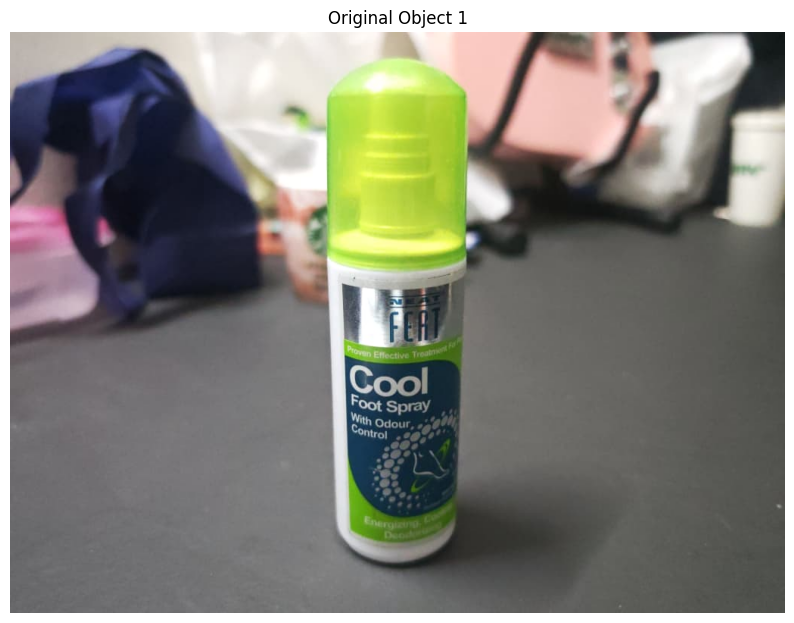

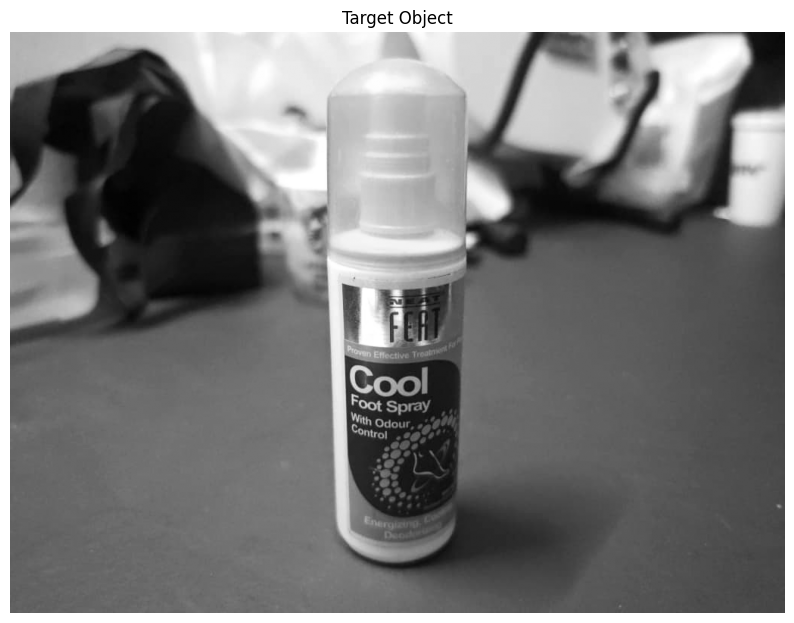

In [44]:
try:
  path1 = "/content/FootSpray.jpeg"
  path2 = "/content/SearchImage.jpeg"
  img1, gray_img1 = prepare_image(path1)
  img2, gray_img2 = prepare_image(path2)
except (FileNotFoundError, ValueError) as e:
  print(e)
else:
  load_image("Original Object 1", img1)
  load_image("Target Object", gray_img1, cmap='gray')

## Step 2: Extract Features using ORB
Here, the computer acts as the detective, identifying keypoints (distinctive corners and edges) and calculating their mathematical descriptors.

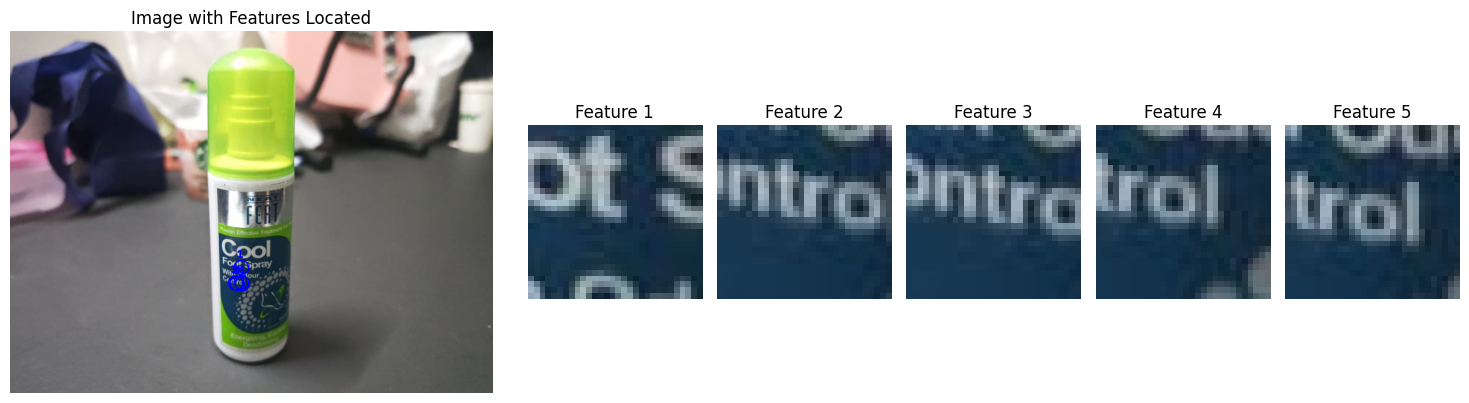

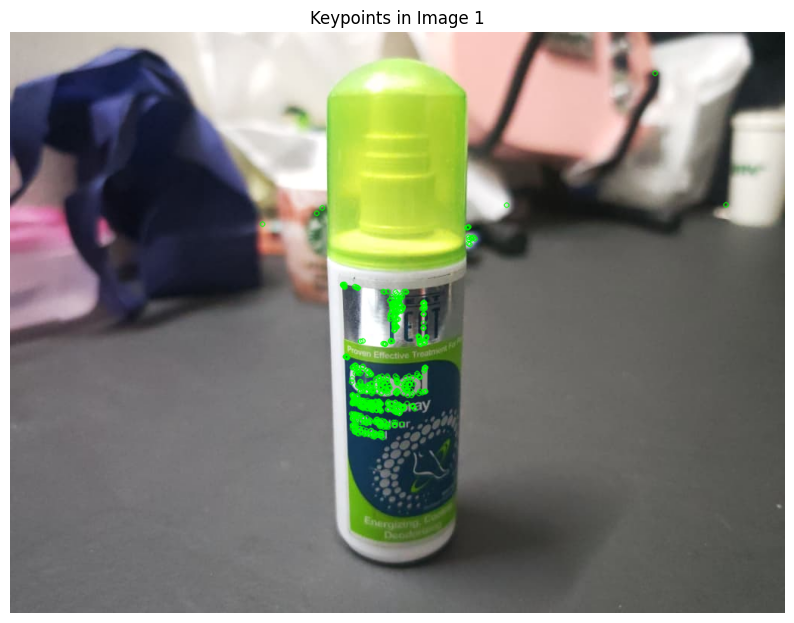

In [45]:
orb = cv2.ORB_create(nfeatures=600) # Initialize ORB detector (finding up to 600 features)

def detect_and_compute_features(img):
        kp, desc = orb.detectAndCompute(img, None)
        return kp, desc

try:
  img1, gray_img1 = prepare_image(path1) # Prepare the first image (load and convert to grayscale)
  img2, gray_img2 = prepare_image(path2) # Prepare the second image (load and convert to grayscale)
except (FileNotFoundError, ValueError) as e:
  print(e)
else:
  # Detect and compute features for both images
  kp_1, desc_1 = detect_and_compute_features(gray_img1)
  kp_2, desc_2 = detect_and_compute_features(gray_img2)

  fig, axes = plt.subplots(1, 6, figsize=(15, 4), gridspec_kw={'width_ratios': [3, 1, 1, 1, 1, 1]}) # Setup the figure with 6 subplots
  img_1_annotated = img1.copy() # Create a copy of the first image to draw keypoints on
  offset = 15 # Offset for placing keypoints in the first image

  # Loop through the first 5 keypoints of the first image and draw them
  for i in range(5):
    kp = kp_1[i]
    x, y = int(kp.pt[0]), int(kp.pt[1]) # Get the coordinates of the keypoint

    # Draw a numbered circle around the keypoint on the first image
    cv2.circle(img_1_annotated, (x, y), offset, (255, 0, 0), 2)
    cv2.putText(
        img_1_annotated,
        str(i + 1),
        (x - 10, y - 20),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.8, (255, 0, 0), 2
    )

    # Crop the pixel patch
    patch = img1[max(0, y - offset) : min(img1.shape[0], y + offset), max(0, x - offset) : min(img1.shape[1], x + offset)]

    # Display the cropped patch in the corresponding subplot
    axes[i + 1].imshow(cv2.cvtColor(patch, cv2.COLOR_BGR2RGB))
    axes[i + 1].set_title(f"Feature {i + 1}")
    axes[i + 1].axis('off') # Turn off axis for the first subplot

  # Display the annotated first image in the first subplot
  axes[0].imshow(cv2.cvtColor(img_1_annotated, cv2.COLOR_BGR2RGB))
  axes[0].set_title("Image with Features Located")
  axes[0].axis('off') # Turn off axis for the first subplot

  plt.tight_layout() # Adjust the layout to prevent overlap
  plt.show() # Show the final figure with all subplots

  # Visualize the keypoints found
  img1_kp = cv2.drawKeypoints(img1, kp_1, None, color=(0, 255, 0), flags=0)
  load_image("Keypoints in Image 1", img1_kp) # Display the keypoints on the first image

## Step 3 & 4: Match Features and Analyze the Results
The computer now compares the descriptors from the cup against the descriptors found in the cluttered scene to find matches.

Number of matches found: 162


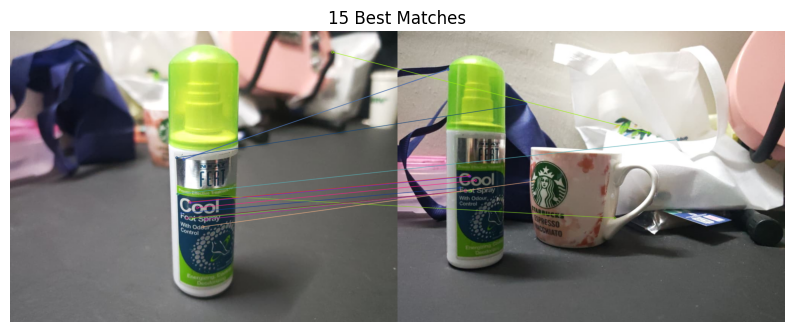

In [46]:
try:
  img1, gray_img1 = prepare_image(path1)
  img2, gray_img2 = prepare_image(path2)
  kp_1, desc_1 = detect_and_compute_features(gray_img1)
  kp_2, desc_2 = detect_and_compute_features(gray_img2)
except (FileNotFoundError, ValueError) as e:
  print(e)
else:
  # Create a BFMatcher object
  bf = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True)

  # Match descriptors
  matches = bf.match(desc_1, desc_2)

  # Sort matches by distance (best matches first)
  matches = sorted(matches, key=lambda x: x.distance)
  print(f"Number of matches found: {len(matches)}")

  # Draw the top 15 best matches to avoid cluttering the image
  img_matches = cv2.drawMatches(
      img1, kp_1,
      img2, kp_2,
      matches[:15], None,
      flags = cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
      )

  load_image("15 Best Matches", img_matches)

#REFLECTION AND DISCUSSION

1. The feature that most useful to finding the object is the word type in the object. It works so well because it's a unique feature that only it has.

2. Yes, there is some feature that was accidently matched the wrong object. One of it is pointing into the cup.

3. Yes, it will works because the object has its own unique features that only it have.